# Emg3d pyGIMLI inversion testing in 3-dimensions

Requires
- `pygimli>=1.5.2`
- ipygimli.py

v4: try to invert for a custom hot plume, with minimal noise, with 1 source & inverting for the whole area around the plume

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, Normalize

import emg3d
import ipygimli as ipygimli
from Emg3d_extra_grid_functions_v26 import *
import pandas as pd
import h5py

In [6]:
#Random number regenerator used to set the noise, seed guarantees the same noise is reproduced each time, can be adapted with different numbers to test different noise
rng_real = np.random.default_rng(seed=0)
rng_imag = np.random.default_rng(seed=1)

## Create synthetic data

Model used in previous forward-modeling (v1), with a cuboid hot plume inside

### Define survey and baseline resistivity model

In [7]:
# Source, y-directed point dipole on the surface
src_coords = (0, -126, 0, 90.0, 0.0)
src = emg3d.surveys.txrx_coordinates_to_dict(emg3d.TxElectricDipole, src_coords)

# Source frequency
frequency = 1

# Receivers, vertical z-directed point dipoles
rec_x = np.arange(1, 41)*0
rec_y = np.array([74]*40)
rec_z = np.arange(1,41)*-7.5
rec_coords = (rec_x, rec_y, rec_z, 0.0, 90.0)
rec = emg3d.surveys.txrx_coordinates_to_dict(emg3d.RxElectricPoint, rec_coords)

# Layer boundaries
# We idealize the depth model here a bit, to have cells of 10m in depth
depth = [0, -50, -80, -120, -190]

# Layer resistivities in Ohm.m for the baseline
resistivities_base = np.array([1e8, 52.0, 38.0, 26.0, 29.5, 17.5]) # base incl. air (lower res, because of 3D modelling)

In [8]:
# define the input that stays the same for all models
inp = {
    'src': src,
    'rec': rec,
    'depth': depth,
    'freqtime': frequency,
    'srcpts': 5,  # Models the finite-length source as 5 point sources with Gaussian Quadrature
    'htarg': {'pts_per_dec': -1},  # Faster computation
    'verb': 1,
    'strength': 1,
}

### Create grids

In [9]:
cgrid = emg3d.construct_mesh(
    center=(0,0,0),                                 # Center of wanted grid
    frequency=frequency,                            # Frequency we will use the grid for
    properties=[25, 1e8],                           # Reference resistivity
    domain=([-100, 100], [-140, 100], [-300, 25]),   # Domain in which we want precise results
    center_on_edge=True,
    min_width_limits = [15, 15, 5],
)
 
cgrid # mesh info
#grid.plot_grid() # plotting the grid

TensorMesh: 524,288 cells

                      MESH EXTENT             CELL WIDTH      FACTOR
  dir    nC        min           max         min       max      max
  ---   ---  ---------------------------  ------------------  ------
   x     64   -102,353.92    102,353.92     15.00 26,438.88    1.35
   y     64   -102,493.09    142,269.02     15.00 39,820.93    1.39
   z    128   -108,798.04    143,051.73      5.00 34,528.69    1.32

In [10]:
#Insert baseline resistivity values into the coarse grid

# Pre-allocate an array with number of cells corresponding to our grid
cres_base = np.ones(cgrid.shape_cells)

# Layered base model: Fill in layered resistivities into our grid and create model
dd = np.r_[np.inf, depth, -np.inf]
for i in range(len(resistivities_base)):
    cres_base[:, :, (cgrid.cell_centers_z > dd[i+1]) & (cgrid.cell_centers_z <= dd[i])] = resistivities_base[i]

cmodel_base = emg3d.Model(cgrid, property_x=cres_base, mapping='Resistivity')
cmodel_base_sigma = emg3d.Model(cgrid, property_x=1/np.array(cres_base), mapping='Conductivity')

In [11]:
fgrid = emg3d.construct_mesh(
    center=(0,-135,0),                                 # Center of wanted grid
    frequency=frequency,                            # Frequency we will use the grid for
    properties=[25, 1e8],                           # Reference resistivity
    domain=([-100, 100], [-140, 100], [-300, 25]),   # Domain in which we want precise results
    center_on_edge=True,
    min_width_limits = [5, 5, 2.5],
)
 
fgrid  # mesh info
#grid.plot_grid() # plotting the grid

TensorMesh: 1,769,472 cells

                      MESH EXTENT             CELL WIDTH      FACTOR
  dir    nC        min           max         min       max      max
  ---   ---  ---------------------------  ------------------  ------
   x     96   -100,983.68    100,983.68      5.00 26,632.29    1.36
   y     96   -102,596.20    102,556.20      5.00 31,281.10    1.44
   z    192   -102,815.47    102,540.47      2.50 26,495.26    1.35

In [12]:
#Insert baseline resistivity values into the fine grid

# Pre-allocate an array with number of cells corresponding to our grid
fres_base = np.ones(fgrid.shape_cells)

# Layered base model: Fill in layered resistivities into our grid and create model
dd = np.r_[np.inf, depth, -np.inf]
for i in range(len(resistivities_base)):
    fres_base[:, :, (fgrid.cell_centers_z > dd[i+1]) & (fgrid.cell_centers_z <= dd[i])] = resistivities_base[i]

fmodel_base = emg3d.Model(fgrid, property_x=fres_base, mapping='Resistivity')
fmodel_base_sigma = emg3d.Model(fgrid, property_x=1/np.array(fres_base), mapping='Conductivity')

### Define scenario to test

In [13]:
#load custom plumes from Excel file

df_loaded = pd.read_excel('Sept2026_plumes.xlsx', sheet_name=None, usecols="B:G", skiprows=1)

keys = df_loaded.keys()
print("Plume templates loaded : ", keys)
print("Dimensions of template : ", np.shape(df_loaded[list(keys)[0]].to_numpy())) #This should give (6,6)

Plume templates loaded :  dict_keys(['Cyl1', 'Cyl2', 'Boy1', 'Boy2', 'Lat1-0', 'Lat1-1', 'Lat1-2', 'Lat2-0', 'Lat2-1', 'Lat2-2'])
Dimensions of template :  (6, 6)


In [14]:
#INPUTS

# How to interpret template values
res_0 = resistivities_base[4]
res_1 = resistivities_base[4]
res_2 = 25
res_3 = 20
res_4 = 14
res_dict = {'0': res_0, '1': res_1, '2': res_2, '3': res_3, '4': res_4}

# How to locate the cells from the template on the grid
r_spacing = 15 #Assuming always that we start from the origin
z_min = -190
z_max = -120
z_spacing = 70/6

# Template to use
key = 'Cyl1'

# Reformat and pad with original aquifer values (for radius which expands further than r_max)
template = np.flip(df_loaded[key].to_numpy(), axis=0)
template_padded = np.ones((10,10), dtype=str)
template_padded[:6, :6] = template
template = template_padded

### True model definition
We interpolate a model to the coarse grid and then interpolate that to the fine grid, so that we avoid inverse crime but also make sure that the true model is describable on both meshes

#### Interpolate template to coarse mesh

In [15]:
# Insert the plume according to the template

# Find indeces of the place to insert the plume
ix_min, iy_min, iz_min, ix_max, iy_max, iz_max = find_cuboid_indeces_xyz(cgrid, x_extent = 100, y_extent=100, zmin = z_min, zmax = z_max)

radii = []
# Go through each cell in the volume and adapt resistivity to the corresponding template value
cres_target = cres_base.copy()
for ix in np.arange(ix_min, ix_max+1):
    for iy in np.arange(iy_min, iy_max+1):
        for iz in np.arange(iz_min, iz_max+1):
            grid_loc = [cgrid.cell_centers_x[ix], cgrid.cell_centers_y[iy], cgrid.cell_centers_z[iz]]
            radius = np.sqrt(grid_loc[0]**2+grid_loc[1]**2)
            temp_ir = int(radius/r_spacing) #int rounds to the integer; this makes sure that the index chooses the innermost cell
            temp_iz = int(-(z_min-grid_loc[2])/z_spacing) #int rounds to the integer; this makes sure that the index chooses the topmost cell
            cres_target[ix, iy, iz] = res_dict[str(template[temp_iz, temp_ir])]

[-99, -99, -189] [99, 99, -121]
x:  -97.50000000000777
y:  -97.49999999999955
z:  -187.49999999999397
x:  97.49999999999223
y:  97.50000000000045
z:  -122.49999999999397


In [16]:
cmodel_target = emg3d.Model(cgrid, property_x=cres_target, mapping='Resistivity')

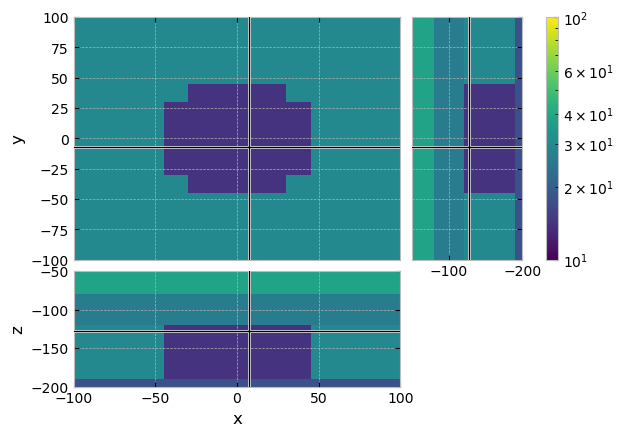

In [17]:
#QC cube location
cgrid.plot_3d_slicer(
    cmodel_target.property_x,
    pcolor_opts={'norm': LogNorm(vmin=1e1, vmax=1e2)},
    xlim=[-100, 100],
    ylim=[-100, 100],
    zlim=[-200, -50],
    zslice=-125,
)
fig = plt.gcf()

NameError: name 'receivers' is not defined

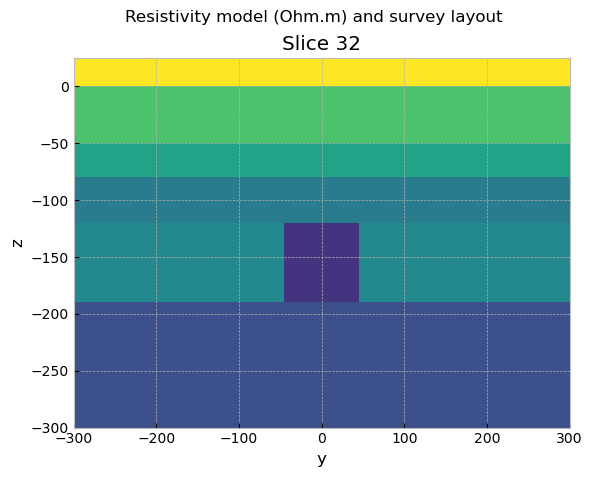

In [18]:
#Focus on the y,z plane
cgrid.plot_slice(
    cmodel_target.property_x,
    normal = 'X',
    pcolor_opts={'norm': LogNorm(vmin=10, vmax=100)},
    range_x=[-300, 300],
    range_y=[-300, 25],
    slice_loc=0
)
fig = plt.gcf()
fig.suptitle('Resistivity model (Ohm.m) and survey layout')
axs = fig.get_children()
axs[1].plot(receivers[1], receivers[2], 'bv', markersize = 10)
axs[1].plot(source[1], source[2], 'r*', markersize = 20)
axs[1].grid(False)

#### Interpolate from coarse to fine mesh

In [19]:
# Interpolate from coarse to fine mesh

# Find indeces of the place to insert the plume for both grids
ix_min, iy_min, iz_min, ix_max, iy_max, iz_max = find_cuboid_indeces_xyz(fgrid, x_extent = 100, y_extent=100, zmin = z_min, zmax = z_max)

# Go through each cell in grid2 and adapt resistivity to the value from grid
fres_target = fres_base.copy()
for ix in np.arange(ix_min, ix_max+1):
    for iy in np.arange(iy_min, iy_max+1):
        for iz in np.arange(iz_min, iz_max+1):
            grid_loc = [fgrid.cell_centers_x[ix], fgrid.cell_centers_y[iy], fgrid.cell_centers_z[iz]]
            c_ix, c_iy, c_iz = point2index_xyz(cgrid, grid_loc, QC=False, Extra_QC=False)
            fres_target[ix, iy, iz] = cres_target[c_ix, c_iy, c_iz]

[-99, -99, -189] [99, 99, -121]
x:  -97.50000000000226
y:  -97.49999999998795
z:  -188.75000000000034
x:  97.49999999999774
y:  97.50000000001205
z:  -121.25000000000034


In [20]:
fmodel_target = emg3d.Model(fgrid, property_x=fres_target, mapping='Resistivity')
fmodel_target_sigma = emg3d.Model(fgrid, property_x=1/np.array(fres_target), mapping='Conductivity')

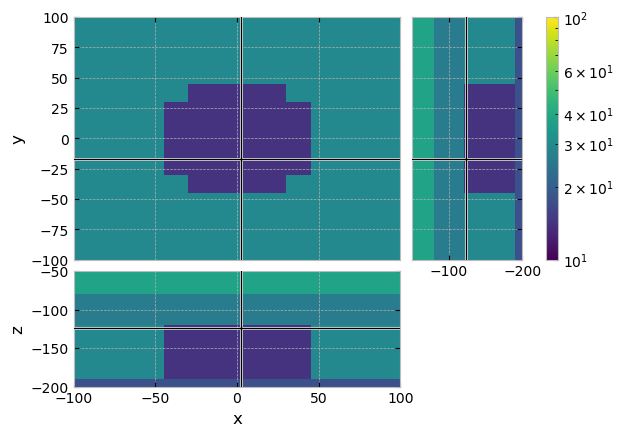

In [21]:
#QC cube location
fgrid.plot_3d_slicer(
    fmodel_target.property_x,
    pcolor_opts={'norm': LogNorm(vmin=1e1, vmax=1e2)},
    xlim=[-100, 100],
    ylim=[-100, 100],
    zlim=[-200, -50],
    zslice=-125,
)
fig = plt.gcf()

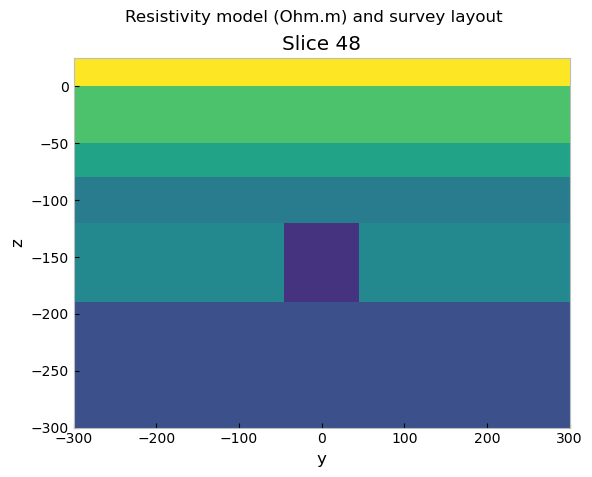

In [24]:
#Focus on the y,z plane
fgrid.plot_slice(
    fmodel_target.property_x,
    normal = 'X',
    pcolor_opts={'norm': LogNorm(vmin=10, vmax=100)},
    range_x=[-300, 300],
    range_y=[-300, 25],
    slice_loc=0
)
fig = plt.gcf()
fig.suptitle('Resistivity model (Ohm.m) and survey layout')
axs = fig.get_children()
#axs[1].plot(receivers[1], receivers[2], 'bv', markersize = 10)
#axs[1].plot(source[1], source[2], 'r*', markersize = 20)
axs[1].grid(False)

### Forward modelling - creating simulated data

Code is based on sensitivity gradient notebook v1_7

We create a simulation class with the true model data + noise as observed data
This is all computed using the fine grid to create accuracy and prevent inverse crime

In [25]:
# Parameterize the noise to be added

noise_floor = 1e-15
relative_error = 0.01
mean_noise = 0.0

In [26]:
#Generate frequency- and source-dependent grids
gopts = {
    'properties': [25, 1e8],
    'min_width_limits': [5, 5, 2.5],
    #'stretching': (None, None, [1.0, 1.5]),
    'domain': (
        [-100, 100],
        [-100, 100],
        [-300, 25]
    ),
    'center_on_edge': False,
}

In [27]:
#We don't include noise yet as we compute it ourselves later

survey = emg3d.surveys.Survey(
    name='Survey forward-modelling',  # Name of the survey
    sources=src,               # Source coordinates
    receivers=rec,             # Receiver coordinates
    frequencies=frequency,   # Two frequencies
    # data=data,               # Adding the observed data here will allow sensitivity calculation later, but we need to generate it first
)

In [28]:
# Simulate with the true model to create the observed data free of noise

simulation = emg3d.simulations.Simulation(
            name='Simulation forward-modelling',    # A name for this simulation
            survey=survey,        # Our survey instance
            model=fmodel_target_sigma,          # The model
            gridding='both',      # Frequency- and source-dependent meshes
            max_workers=1,        # How many parallel jobs
            # solver_opts,        # Any parameter to pass to emg3d.solve
            gridding_opts=gopts,  # Gridding options
            receiver_interpolation = "linear" #Needed for correct computation of the gradient
        )

simulation.compute(observed=True)
#The simulation should now contain observed data (+noise), synthetic data (without noise) and standard deviation values
#The survey class is also updated with this information

Compute efields            0/1  [00:00]

In [24]:
# Compute the noise and overwrite the data, based on empymod+pygimli testing

dobs = survey.data['synthetic']

# Add random white noise to dobs
std_dev_real = np.sqrt(noise_floor**2 + np.abs(relative_error*dobs.real)**2)
std_dev_imag = np.sqrt(noise_floor**2 + np.abs(relative_error*dobs.imag)**2)
noise_real = rng_real.normal(loc=0, scale=std_dev_real, size = dobs.shape)
noise_imag = rng_imag.normal(loc=0, scale=std_dev_imag, size = dobs.shape)
std_dev = std_dev_real + 1j*std_dev_imag
noise = noise_real + 1j*noise_imag
dobs += noise
dobs0 = dobs
noise0 = noise

# Overwrite values in survey
survey.data['observed'] = dobs
survey.standard_deviation = std_dev

### Inversion - defining the starting model

Now we create a simulation class with the true model data + noise as the observed data and the starting model data without noise as the synthetic data.

We use the coarse grid in all inversion-related steps, taking only the observed data values with us from fine grid computation

In [25]:
survey2 = emg3d.surveys.Survey(
    name='Survey to go into inversion',  # Name of the survey
    sources=src,               # Source coordinates
    receivers=rec,             # Receiver coordinates
    frequencies=frequency,   # Two frequencies
    data=survey.data['observed'], # Adding the observed data here will allow sensitivity calculation later, but we need to generate it first
)
survey2.standard_deviation = survey.standard_deviation

In [26]:
simulation2 = emg3d.simulations.Simulation(
            name='Simulation to go into inversion',    # A name for this simulation
            survey=survey2,        # Our survey instance
            model=cmodel_base_sigma,          # The model
            gridding='both',      # Frequency- and source-dependent meshes
            max_workers=1,        # How many parallel jobs
            # solver_opts,        # Any parameter to pass to emg3d.solve
            gridding_opts=gopts,  # Gridding options
            receiver_interpolation = "linear", #Needed for correct computation of the gradient
            tqdm_opts = False #To switch-off progress bar during inversion
        )

simulation2.compute(observed=False)
#We don't put observed=True in this case because this will overwrite the observed data saved inside the survey

(179.5, 180.0)

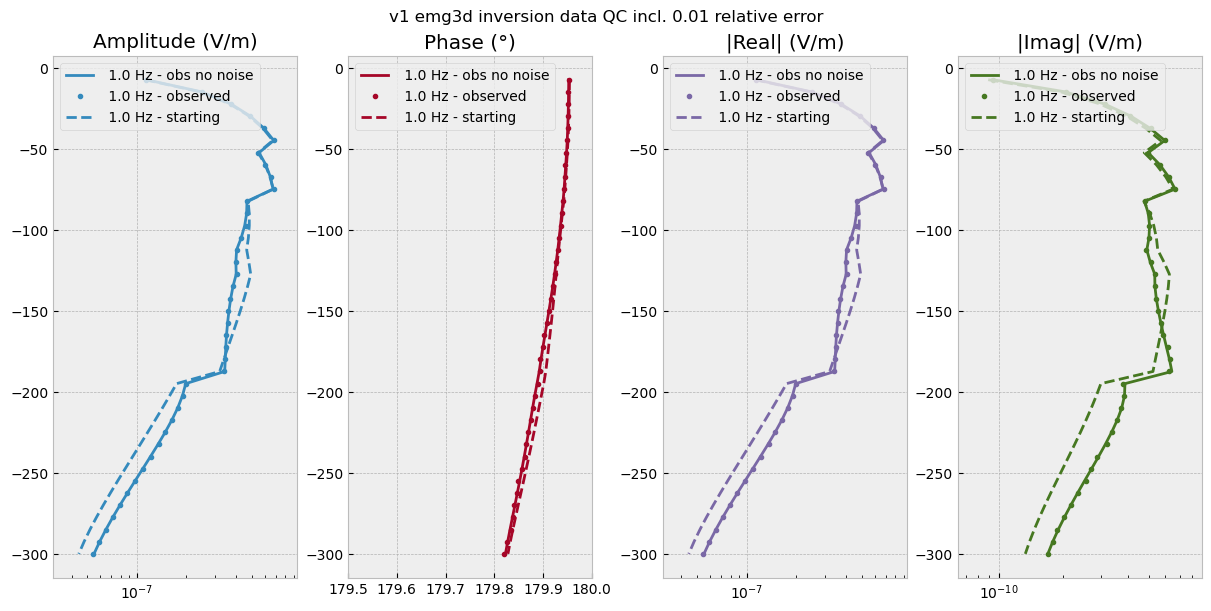

In [27]:
# QC data
dobs = np.array(dobs0)[0,:,0]
noise = np.array(noise0)[0,:,0]
dhalf = np.array(survey2.data['synthetic'])[0,:,0]

# Plot it
fig, (ax2, ax3, ax4, ax5) = plt.subplots(1, 4, figsize=(12, 6), constrained_layout=True)
axes = [ax2, ax3, ax4, ax5]


plt.locator_params(axis='x', nbins=3)

#Plot measured data
labels = ['Amplitude (V/m)', 'Phase (°)', '|Real| (V/m)', '|Imag| (V/m)']
data_obs = [np.abs(dobs), np.angle(dobs,deg=True), abs(dobs.real), abs(dobs.imag)]
data0 = [np.abs(dobs-noise), np.angle(dobs-noise,deg=True), abs((dobs-noise).real), abs((dobs-noise).imag)]
data_half = [np.abs(dhalf), np.angle(dhalf,deg=True), abs(dhalf.real), abs(dhalf.imag)]
fig.suptitle("v1 emg3d inversion data QC incl. "+str(relative_error)+" relative error")
for j in np.arange(len(labels)):
    ax = axes[j]
    ax.set_title(labels[j])
    ax.plot(data0[j][:], rec_coords[2], 'C'+str(j)+'-', label = f"{frequency: 2.1f} Hz - obs no noise")
    ax.plot(data_obs[j][:], rec_coords[2], 'C'+str(j)+'.', label=f"{frequency: 2.1f} Hz - observed")
    ax.plot(data_half[j][:], rec_coords[2], 'C'+str(j)+'--', label=f"{frequency: 2.1f} Hz - starting")
    ax.legend(loc='upper left')
    ax.set_xscale('log')
    xmin, xmax = ax.get_xlim()
    ax.set_xlim([xmin*0.8, xmax*1.2])
    
ax3.set_xscale('linear')
ax3.set_xlim([179.5, 180])
#The noise looks very acceptable

## Define regions, instantiate Kernel and Inversion

We only invert for the value of the anomaly, not the location, by marking the region of the anomaly and using single=True in pyGIMLi's region manager

In [ ]:
# Create markers to define the center region

# Find indeces of the center region
ix_min, iy_min, iz_min, ix_max, iy_max, iz_max = find_cuboid_indeces_xyz(cgrid, x_extent = 100, y_extent=100, zmin = z_min, zmax = z_max)

# Create region markers
markers = np.zeros(simulation2.model.shape, dtype=int)
markers[ix_min:ix_max+1, iy_min:iy_max+1, iz_min:iz_max+1] = 1 # Only center region is inverted for

[-99, -99, -189] [99, 99, -121]
x:  -97.50000000000777
y:  -97.49999999999955
z:  -187.49999999999397
x:  97.49999999999223
y:  97.50000000000045
z:  -122.49999999999397


In [33]:
print(np.shape(markers[ix_min:ix_max, iy_min:iy_max, iz_min:iz_max]))

(13, 13, 13)


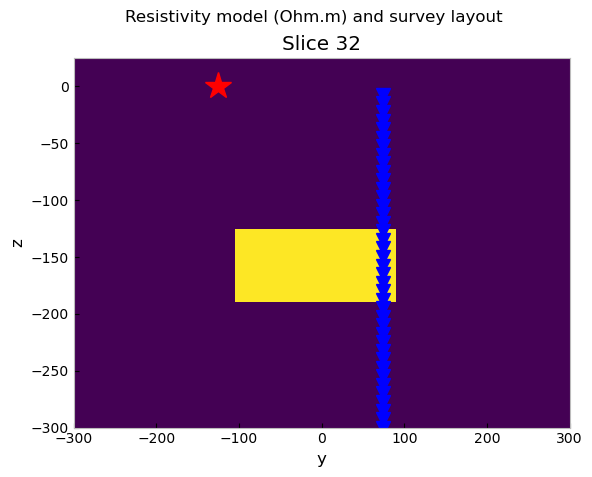

In [29]:
# QC the inversion region corresponds to the wanted region
# #Focus on the y,z plane
cgrid.plot_slice(
    markers,
    normal = 'X',
    #pcolor_opts={'norm': LogNorm(vmin=10, vmax=100)},
    range_x=[-300, 300],
    range_y=[-300, 25],
#    slice_loc=0
)
fig = plt.gcf()
fig.suptitle('Resistivity model (Ohm.m) and survey layout')
axs = fig.get_children()
axs[1].plot(rec_coords[1], rec_coords[2], 'bv', markersize = 10)
axs[1].plot(src_coords[1], src_coords[2], 'r*', markersize = 20)
axs[1].grid(False)

In [30]:
# Instantiate the emg3d-kernel for pyGIMLi
fop = ipygimli.Kernel(simulation=simulation2, markers=markers, pgthreads=1)

# Instantiate the inversion and set some inversion parameters
INV = ipygimli.Inversion(fop=fop)
#INV.inv.setCGLSTolerance(1)  # is _absolute_, not _relative_
INV.inv.setMaxCGLSIter(10)

# Set the regions.
INV.fop.setRegionProperties(1, limits=(0.01, 2)) # Center region
INV.fop.setRegionProperties(0, background=True) # Background

## Run inversion

In [31]:
INV.run(
    #maxIter=2, # just to test
    lam=40,  # btw 1-100
    lambdaFactor=10,
    stopAtChi1=False,
    dPhi=5.0,
    #verbose=True,
    #debug=True,
    #startModel=model.property_x.ravel('F'),
    #isReference=True, 
)

04/10/26 - 18:11:10 - pyGIMLi - INFO - :: pyGIMLi(emg3d) START ::
04/10/26 - 18:11:46 - pyGIMLi - INFO - ===========================================================================
                                        it   F(m)         χ²          λ         ϕᵈ         ϕᵐ   ϕ=ϕᵈ+λϕᵐ   Δϕ (%)
                                       ---------------------------------------------------------------------------
04/10/26 - 18:11:46 - pyGIMLi - INFO -   0      1      259.2       40.0    20732.4        0.0    20732.4     0.00
04/10/26 - 18:36:21 - pyGIMLi - INFO -   1     25       21.9       40.0     1749.1       45.8     3582.4    82.72
04/10/26 - 19:12:29 - pyGIMLi - INFO -   2     24       66.1      400.0     5284.5        7.4     8241.0  -130.04
04/10/26 - 19:46:52 - pyGIMLi - INFO -   3     24      130.3     4000.0    10425.5        0.4    11964.4   -45.18
04/10/26 - 19:46:52 - pyGIMLi - INFO - :: pyGIMLi(emg3d) END   :: runtime = 1:35:42


# Plots

In [3]:
# Load relevant inversion parameters saved through post_step (ipygimli functionality)

inv_data = h5py.File("Simulation to go into inversion.h5",'r')

phi_history = []
for i in np.arange(len(INV.modelHistory)):
    phi_history.append(int(np.array(inv_data['invinfo'][str(i)]['phi'])))

print(phi_history)

NameError: name 'h5py' is not defined

In [4]:
print(inv_data.keys())

NameError: name 'inv_data' is not defined

In [1]:
fig, ax = plt.subplots()

ax.plot(INV.chi2History)
ax.tick_params(axis='y', labelcolor='C0')
ax.set_ylabel('Chi2_history', color = 'C0')
ax2 = ax.twinx()
ax2.plot(phi_history, c = 'red')
ymin, ymax = ax2.get_ylim()
ax2.set_ylim([ymin*1.1, ymax*1.1])
ax2.tick_params(axis='y', labelcolor='red')
ax2.set_ylabel('Phi_history', c='red')
ax.set_title('Inversion information')

NameError: name 'plt' is not defined

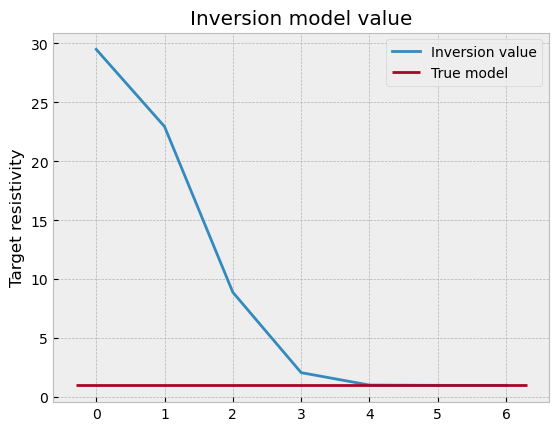

In [ ]:

center_index = point2_index_xyz(cgrid, )

fig, ax = plt.subplots()

ax.plot(1/np.array(INV.modelHistory), label='Inversion value')
ax.set_ylabel('Target resistivity')
ax.set_title('Inversion model value')
xmin, xmax = ax.get_xlim()
ax.hlines(y = res_target, xmin=xmin, xmax=xmax, color='C1', label= 'True model')
ax.legend()

Text(0.5, 0.98, 'Resistivity models (Ohmm) per iteration')

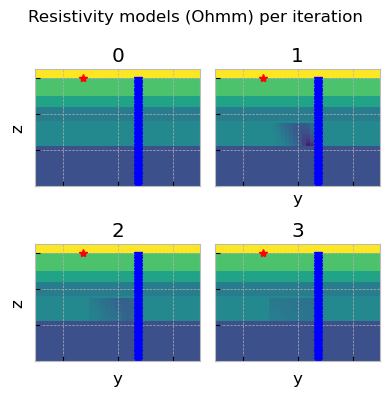

In [44]:
#Code adapted from plot_models function in sampledata.py

sim_amount = len(INV.chi2History)
n_rows = 2
n_columns = 2
depth = 150
vmin = 10
vmax = 100

popts = {'cmap': 'viridis', 'norm': LogNorm(vmin=vmin, vmax=vmax)} #Normalize(vmin=vmin, vmax=vmax)}
# popts2 = {'edgecolors': 'grey', 'linewidth': 0.5, 'cmap': 'Spectral_r',
#           'norm': LogNorm(vmin=0.1, vmax=1000)}
opts = {'v_type': 'CC', 'normal': 'X', 'range_x': [-300, 300], 'range_y': [-300, 25],}

fig, axs = plt.subplots(n_rows, n_columns, figsize=(n_columns*2, n_rows*2), tight_layout=True, sharex = True, sharey = True)

for i in np.arange(sim_amount):
    ax=axs[int((i-i%n_columns)/n_columns), i%n_columns]
    m_it = 1/fop.model2emg3d(INV.modelHistory[i])

    # Plotting the model
    out = cgrid.plot_slice(m_it, ax=ax, pcolor_opts=popts, **opts)
    ax.set_title(str(i))
    ax.plot(rec_coords[1], rec_coords[2], 'bv')
    ax.plot(src_coords[1], src_coords[2], 'r*')
    if i%n_columns != 0:
        ax.set_ylabel('')
        ax.set_yticklabels([])
        if i%n_columns == n_rows:
            plt.colorbar(out[0], ax=ax)#, fraction=.5, shrink=.8, aspect=30)
    
for i in np.arange(sim_amount-1-n_columns):
        ax=axs[int((i-i%n_columns)/n_columns), i%n_columns]
        ax.set_xlabel('')
        ax.set_xticklabels([])

    #for ax in axs.ravel():
    #    ax.axis('equal')
fig.suptitle('Resistivity models (Ohmm) per iteration')



(179.5, 180.0)

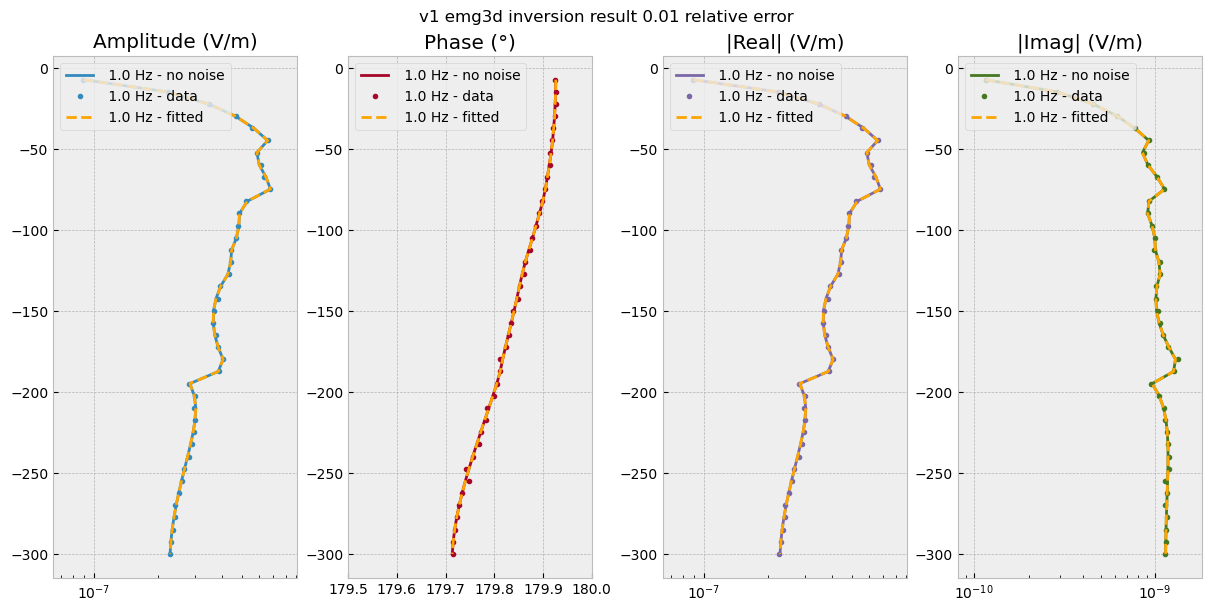

In [ ]:
# QC data
dobs = np.array(dobs0)[0,:,0]
noise = np.array(noise0)[0,:,0]
response = simulation2.survey.data.synthetic[0,:,0]

# Plot it
fig, (ax2, ax3, ax4, ax5) = plt.subplots(1, 4, figsize=(12, 6), constrained_layout=True)
axes = [ax2, ax3, ax4, ax5]


plt.locator_params(axis='x', nbins=3)

#Plot measured data
labels = ['Amplitude (V/m)', 'Phase (°)', '|Real| (V/m)', '|Imag| (V/m)']
data_obs = [np.abs(dobs), np.angle(dobs,deg=True), abs(dobs.real), abs(dobs.imag)]
data0 = [np.abs(dobs-noise), np.angle(dobs-noise,deg=True), abs((dobs-noise).real), abs((dobs-noise).imag)]
data_inv = [np.abs(response), np.angle(response,deg=True), abs(response.real), abs(response.imag)]
fig.suptitle("v1 emg3d inversion result "+str(relative_error)+" relative error")
for j in np.arange(len(labels)):
    ax = axes[j]
    ax.set_title(labels[j])
    ax.plot(data0[j][:], rec_coords[2], 'C'+str(j)+'-', label = f"{frequency: 2.1f} Hz - no noise")
    ax.plot(data_obs[j][:], rec_coords[2], 'C'+str(j)+'.', label=f"{frequency: 2.1f} Hz - data")
    ax.plot(data_inv[j][:], rec_coords[2], color= 'orange', linestyle='--', label=f"{frequency: 2.1f} Hz - fitted")
    ax.legend(loc='upper left')
    ax.set_xscale('log')
    xmin, xmax = ax.get_xlim()
    ax.set_xlim([xmin*0.8, xmax*1.2])
    
ax3.set_xscale('linear')
ax3.set_xlim([179.5, 180])
#The noise looks very acceptable

(179.5, 180.0)

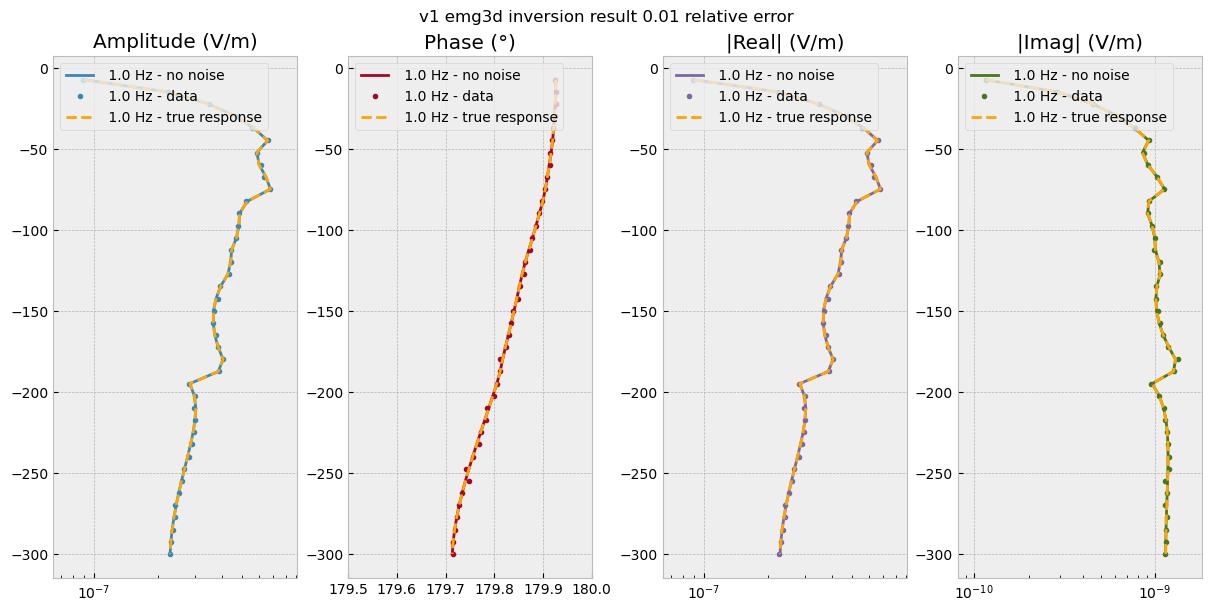

In [ ]:
# QC data
dobs = np.array(dobs0)[0,:,0]
noise = np.array(noise0)[0,:,0]

response = fop.data2emg3d(fop.response(fop.model2gimli(model_target2_conductivity.property_x)))[0,:,0]

# Plot it
fig, (ax2, ax3, ax4, ax5) = plt.subplots(1, 4, figsize=(12, 6), constrained_layout=True)
axes = [ax2, ax3, ax4, ax5]


plt.locator_params(axis='x', nbins=3)

#Plot measured data
labels = ['Amplitude (V/m)', 'Phase (°)', '|Real| (V/m)', '|Imag| (V/m)']
data_obs = [np.abs(dobs), np.angle(dobs,deg=True), abs(dobs.real), abs(dobs.imag)]
data0 = [np.abs(dobs-noise), np.angle(dobs-noise,deg=True), abs((dobs-noise).real), abs((dobs-noise).imag)]
data_inv = [np.abs(response), np.angle(response,deg=True), abs(response.real), abs(response.imag)]
fig.suptitle("v1 emg3d inversion result "+str(relative_error)+" relative error")
for j in np.arange(len(labels)):
    ax = axes[j]
    ax.set_title(labels[j])
    ax.plot(data0[j][:], rec_coords[2], 'C'+str(j)+'-', label = f"{frequency: 2.1f} Hz - no noise")
    ax.plot(data_obs[j][:], rec_coords[2], 'C'+str(j)+'.', label=f"{frequency: 2.1f} Hz - data")
    ax.plot(data_inv[j][:], rec_coords[2], color= 'orange', linestyle='--', label=f"{frequency: 2.1f} Hz - true response")
    ax.legend(loc='upper left')
    ax.set_xscale('log')
    xmin, xmax = ax.get_xlim()
    ax.set_xlim([xmin*0.8, xmax*1.2])
    
ax3.set_xscale('linear')
ax3.set_xlim([179.5, 180])
#The noise looks very acceptable

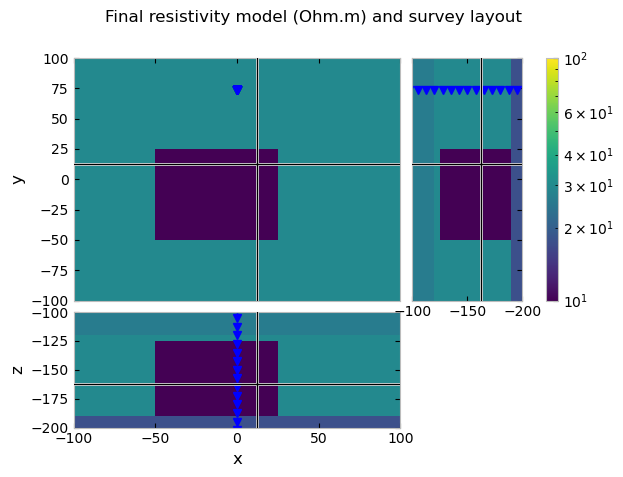

In [ ]:
#QC cube location
grid.plot_3d_slicer(
    1/fop.model2emg3d(INV.modelHistory[-1]),
    pcolor_opts={'norm': LogNorm(vmin=10, vmax=100)},
    xlim=[-100, 100],
    ylim=[-100, 100],
    zlim=[-200, -100],
    zslice=-160,
)
# Plot survey in figure above
fig = plt.gcf()
fig.suptitle('Final resistivity model (Ohm.m) and survey layout')
axs = fig.get_children()
axs[1].plot(rec_coords[0], rec_coords[1], 'bv')
axs[2].plot(rec_coords[0], rec_coords[2], 'bv')
axs[3].plot(rec_coords[2], rec_coords[1], 'bv')
axs[1].plot(src_coords[0], src_coords[1], 'r*')
axs[2].plot(src_coords[0], src_coords[2], 'r*')
axs[3].plot(src_coords[2], src_coords[1], 'r*')
axs[1].grid(False)
axs[2].grid(False)
axs[3].grid(False)

In [32]:
#Custom plume model

model1 = crop_model(1/fop.model2emg3d(INV.fop.jacobian()), grid, x_slice = 0, y_extent=100, zmin=-200, zmax=-100)
model2 = crop_model(1/fop.model2emg3d(INV.fop.jacobian()), grid, x_slice = 0, y_extent=100, zmin=-200, zmax=-100)
model3 = crop_model(1/fop.model2emg3d(INV.fop.jacobian()), grid, x_slice = 0, y_extent=100, zmin=-200, zmax=-100)

manual_plot_slice_3x(model1, model2, model3, y_extent=-100, zmin=-200, zmax=-100, size_y = 6.4, size_z = 4.8, vmin = 1e1, vmax = 1e2)

RuntimeError: ./core/src/matrix.h:466		GIMLI::Vector<ValueType2>& GIMLI::Matrix<ValueType>::rowRef(GIMLI::Index) [with ValueType = double; GIMLI::Index = long long unsigned int]  80 <= 80

In [33]:
A = INV.fop.jacobian()
jacobians = pg.sparseMatrix2Array(A)
#print(A)
#A*np.arange(1
#print(np.shape(np.sum(INV.fop.jacobian(), axis=0)))

NameError: name 'pg' is not defined

In [26]:
def crop_model(model3D, grid, x_slice = 0, y_extent=300, zmin=-250, zmax=0):

    #This method assumes cell_centers are the relevant parameters
    ix_min, iy_min, iz_min, ix_max, iy_max, iz_max = find_cuboid_indeces_xyz(grid, x_slice, y_extent, zmin, zmax, QC=True)

    #QC the bounds
    print('x position: ', grid.cell_centers_x[ix_max])
    print('y_bounds: ', grid.cell_centers_y[iy_min], ' , ', grid.cell_centers_y[iy_max])
    print('z_bounds: ', grid.cell_centers_z[iz_min], ' , ', grid.cell_centers_z[iz_max])

    # Crop Ez field array
    crop_model3D = model3D[ix_max, iy_min:iy_max, iz_min:iz_max]
    crop_model3D = np.flip(np.transpose(crop_model3D), axis=0)

    return crop_model3D

In [26]:
from sampledata import *

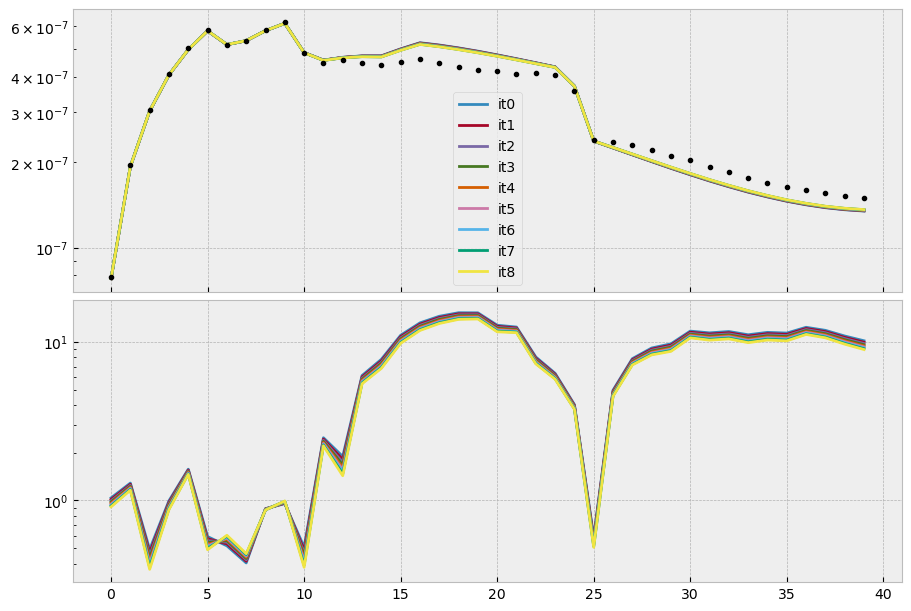

In [28]:
plot_responses(simulation2)

In [8]:
emg3d.Report()

--------------------------------------------------------------------------------
  Date: Tue Sep 10 17:08:40 2024 CEST

                OS : Linux (Ubuntu 22.04)
            CPU(s) : 16
           Machine : x86_64
      Architecture : 64bit
               RAM : 31.0 GiB
       Environment : Jupyter
       File system : ext4

  Python 3.11.9 | packaged by conda-forge | (main, Apr 19 2024, 18:36:13) [GCC
  12.3.0]

             numpy : 1.26.4
             scipy : 1.14.0
             numba : 0.59.1
             emg3d : 1.8.4.dev6+gd2f88de
           empymod : 2.3.1
            xarray : 2024.6.0
        discretize : 0.10.0
              h5py : 3.11.0
        matplotlib : 3.9.1
              tqdm : 4.66.4
           IPython : 8.26.0
           pygimli : 1.5.2
            pgcore : 1.5.0
--------------------------------------------------------------------------------